<a href="https://colab.research.google.com/github/codebreaker0511/skills-introduction-to-github/blob/main/rcnn_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import torch
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.transforms import functional as F
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np
from PIL import Image


In [3]:
import requests, zipfile, io, os

# Download Penn-Fudan Pedestrian dataset
url = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
response = requests.get(url)

# Extract zip into ./data/
z = zipfile.ZipFile(io.BytesIO(response.content))
z.extractall("./data")

# Set up paths
root = "./data/PennFudanPed"
img_folder = os.path.join(root, "PNGImages")
mask_folder = os.path.join(root, "PedMasks")

# List files
img_files = sorted(os.listdir(img_folder))
mask_files = sorted(os.listdir(mask_folder))

print("Total images:", len(img_files))
print("Sample image:", img_files[0])
print("Sample mask:", mask_files[0])


Total images: 170
Sample image: FudanPed00001.png
Sample mask: FudanPed00001_mask.png


In [5]:
import os
import urllib.request
import zipfile

# Download Penn-Fudan dataset
if not os.path.exists("PennFudanPed.zip"):
    url = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
    urllib.request.urlretrieve(url, "PennFudanPed.zip")

# Extract
if not os.path.exists("PennFudanPed"):
    with zipfile.ZipFile("PennFudanPed.zip", "r") as zip_ref:
        zip_ref.extractall(".")


In [6]:
import numpy as np
import torch
from PIL import Image
from torchvision.transforms import functional as F

# returns img tensor and target dict for index i
def get_item(i):
    img_path  = os.path.join(img_folder,  img_files[i])
    mask_path = os.path.join(mask_folder, mask_files[i])

    img  = Image.open(img_path).convert("RGB")
    mask = np.array(Image.open(mask_path))  # each person has a unique id (>0)

    obj_ids = np.unique(mask)
    obj_ids = obj_ids[obj_ids != 0]  # remove background

    boxes, labels = [], []
    for oid in obj_ids:
        ys, xs = np.where(mask == oid)
        if ys.size == 0 or xs.size == 0:
            continue
        xmin, xmax = xs.min(), xs.max()
        ymin, ymax = ys.min(), ys.max()
        boxes.append([xmin, ymin, xmax, ymax])
        labels.append(1)  # single class: pedestrian

    target = {
        "boxes": torch.as_tensor(boxes, dtype=torch.float32),
        "labels": torch.as_tensor(labels, dtype=torch.int64),
    }
    return F.to_tensor(img), target

# quick test
img0, tgt0 = get_item(0)
print("img0:", img0.shape, "boxes:", tgt0["boxes"].shape, "labels:", tgt0["labels"].shape)


img0: torch.Size([3, 536, 559]) boxes: torch.Size([2, 4]) labels: torch.Size([2])


In [7]:
import torch
torch.manual_seed(0)

N = len(img_files)
indices = torch.randperm(N).tolist()
train_idx = indices[: max(1, int(0.75 * N))]
test_idx  = indices[max(1, int(0.75 * N)) :]

print(f"Train: {len(train_idx)}  Test: {len(test_idx)}")

# simple helper to yield mini-batches of indices
def batches(index_list, batch_size):
    for i in range(0, len(index_list), batch_size):
        yield index_list[i:i+batch_size]


Train: 127  Test: 43


In [8]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# model with pretrained weights
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")

# replace head for 2 classes (background + pedestrian)
num_classes = 2
in_feats = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_feats, num_classes)

model.to(device)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)


Device: cuda
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 125MB/s]


In [9]:
num_epochs = 5
batch_size = 2

for epoch in range(1, num_epochs + 1):
    model.train()
    running = 0.0
    for step, batch_ids in enumerate(batches(train_idx, batch_size), 1):
        imgs = []
        tgts = []
        for i in batch_ids:
            img, tgt = get_item(i)
            imgs.append(img.to(device))
            tgts.append({k: v.to(device) for k, v in tgt.items()})

        loss_dict = model(imgs, tgts)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running += float(loss.item())
        if step % 10 == 0:
            print(f"Epoch {epoch} | Step {step} | Loss {running/10:.4f}")
            running = 0.0

    scheduler.step()

print("Training done ✅")


Epoch 1 | Step 10 | Loss 0.5670
Epoch 1 | Step 20 | Loss 0.2388
Epoch 1 | Step 30 | Loss 0.2190
Epoch 1 | Step 40 | Loss 0.1566
Epoch 1 | Step 50 | Loss 0.1637
Epoch 1 | Step 60 | Loss 0.1444
Epoch 2 | Step 10 | Loss 0.1368
Epoch 2 | Step 20 | Loss 0.0993
Epoch 2 | Step 30 | Loss 0.1149
Epoch 2 | Step 40 | Loss 0.0868
Epoch 2 | Step 50 | Loss 0.1135
Epoch 2 | Step 60 | Loss 0.1231
Epoch 3 | Step 10 | Loss 0.1328
Epoch 3 | Step 20 | Loss 0.1005
Epoch 3 | Step 30 | Loss 0.0937
Epoch 3 | Step 40 | Loss 0.0755
Epoch 3 | Step 50 | Loss 0.0867
Epoch 3 | Step 60 | Loss 0.1079
Epoch 4 | Step 10 | Loss 0.1065
Epoch 4 | Step 20 | Loss 0.0597
Epoch 4 | Step 30 | Loss 0.0705
Epoch 4 | Step 40 | Loss 0.0515
Epoch 4 | Step 50 | Loss 0.0637
Epoch 4 | Step 60 | Loss 0.0662
Epoch 5 | Step 10 | Loss 0.0731
Epoch 5 | Step 20 | Loss 0.0483
Epoch 5 | Step 30 | Loss 0.0628
Epoch 5 | Step 40 | Loss 0.0468
Epoch 5 | Step 50 | Loss 0.0558
Epoch 5 | Step 60 | Loss 0.0625
Training done ✅


In [10]:
model.eval()  # set to eval mode

@torch.no_grad()
def get_predictions(idx, score_thresh=0.5):
    img, target = get_item(idx)
    img = img.to(device)
    pred = model([img])[0]

    # Filter boxes with score > threshold
    keep = pred['scores'] > score_thresh
    boxes  = pred['boxes'][keep].cpu()
    labels = pred['labels'][keep].cpu()
    scores = pred['scores'][keep].cpu()

    return img.cpu(), boxes, labels, scores


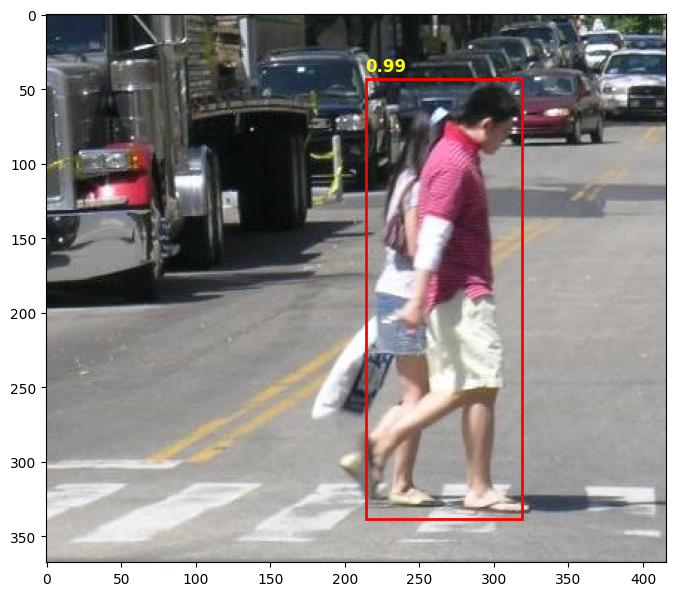

In [13]:
import torch
import torchvision.ops as ops
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Pick a test image
idx = test_idx[1]  # change index to see a different image
img, boxes, labels, scores = get_predictions(idx, score_thresh=0.5)

# Apply NMS
keep = ops.nms(boxes, scores, iou_threshold=0.5)
boxes = boxes[keep]
scores = scores[keep]

# Plot
fig, ax = plt.subplots(1, figsize=(8, 8))
ax.imshow(img.permute(1,2,0))  # CHW -> HWC

for i, box in enumerate(boxes):
    x1, y1, x2, y2 = box
    rect = patches.Rectangle(
        (x1, y1), x2-x1, y2-y1,
        linewidth=2, edgecolor='r', facecolor='none'
    )
    ax.add_patch(rect)
    ax.text(x1, y1-5, f"{scores[i]:.2f}", color='yellow', fontsize=12, weight='bold')

plt.show()


In [14]:
from torchvision.ops import box_iou

def evaluate(test_idx, iou_thresh=0.5, score_thresh=0.5):
    tp, fp, fn = 0, 0, 0
    for idx in test_idx:
        img, target = get_item(idx)
        gt_boxes = target['boxes']

        _, pred_boxes, _, pred_scores = get_predictions(idx, score_thresh=score_thresh)

        if len(pred_boxes) == 0:
            fn += len(gt_boxes)
            continue

        ious = box_iou(pred_boxes, gt_boxes)
        matches = (ious > iou_thresh).sum(dim=0)  # match GT

        tp += matches.sum().item()
        fp += len(pred_boxes) - matches.sum().item()
        fn += len(gt_boxes) - matches.sum().item()

    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)
    print(f"Precision: {precision:.4f}, Recall: {recall:.4f}")

evaluate(test_idx)


Precision: 0.8702, Recall: 0.9828


In [15]:
import torch
from torchvision.ops import box_iou, nms

def apply_nms(boxes, scores, iou_thresh=0.5):
    if boxes.numel() == 0:
        return boxes, scores
    keep = nms(boxes, scores, iou_thresh)
    return boxes[keep], scores[keep]


In [16]:
def compute_ap(gt_boxes, pred_boxes, pred_scores, iou_thresh=0.5):
    if pred_boxes.numel() == 0:
        return 0.0

    # Sort predictions by score descending
    sorted_idx = torch.argsort(pred_scores, descending=True)
    pred_boxes = pred_boxes[sorted_idx]

    tp = torch.zeros(len(pred_boxes))
    fp = torch.zeros(len(pred_boxes))
    detected = torch.zeros(len(gt_boxes))  # keep track of matched GT

    ious = box_iou(pred_boxes, gt_boxes)  # shape [num_pred, num_gt]

    for i in range(len(pred_boxes)):
        max_iou, max_idx = ious[i].max(0)
        if max_iou >= iou_thresh and detected[max_idx]==0:
            tp[i] = 1
            detected[max_idx] = 1
        else:
            fp[i] = 1

    # Cumulative sums
    tp_cum = torch.cumsum(tp, dim=0)
    fp_cum = torch.cumsum(fp, dim=0)
    precision = tp_cum / (tp_cum + fp_cum + 1e-6)
    recall = tp_cum / (len(gt_boxes) + 1e-6)

    # AP: 11-point interpolation (simplified)
    ap = 0.0
    for r_thresh in torch.linspace(0,1,11):
        p = precision[recall>=r_thresh].max() if (recall>=r_thresh).any() else 0
        ap += p / 11.0
    return ap.item()


In [17]:
def evaluate_map(test_idx, iou_thresh=0.5, score_thresh=0.5):
    aps = []
    for idx in test_idx:
        img, target = get_item(idx)
        gt_boxes = target['boxes']
        _, pred_boxes, _, pred_scores = get_predictions(idx, score_thresh)
        pred_boxes, pred_scores = apply_nms(pred_boxes, pred_scores, iou_thresh)
        ap = compute_ap(gt_boxes, pred_boxes, pred_scores, iou_thresh)
        aps.append(ap)

    mean_ap = sum(aps)/len(aps)
    print(f"mAP@IoU{iou_thresh}: {mean_ap:.4f}")

evaluate_map(test_idx)


mAP@IoU0.5: 0.8901


In [18]:
def evaluate_recall(test_idx, iou_thresh=0.5, score_thresh=0.5):
    tp_total, gt_total = 0, 0
    for idx in test_idx:
        img, target = get_item(idx)
        gt_boxes = target['boxes']
        _, pred_boxes, _, pred_scores = get_predictions(idx, score_thresh)
        pred_boxes, pred_scores = apply_nms(pred_boxes, pred_scores, iou_thresh)

        if len(pred_boxes) == 0:
            continue

        ious = box_iou(pred_boxes, gt_boxes)
        matches = (ious > iou_thresh).any(dim=0)
        tp_total += matches.sum().item()
        gt_total += len(gt_boxes)

    recall = tp_total / (gt_total + 1e-6)
    print(f"Recall@IoU{iou_thresh}: {recall:.4f}")

evaluate_recall(test_idx)


Recall@IoU0.5: 0.9655


In [19]:
multi_obj_idx = None
for i, fname in enumerate(os.listdir(img_folder)):
    _, target = get_item(i)
    if len(target["boxes"]) > 1:
        multi_obj_idx = i
        break

print("Index chosen:", multi_obj_idx, "Filename:", os.listdir(img_folder)[multi_obj_idx])


Index chosen: 0 Filename: PennPed00033.png


In [20]:
img, target = get_item(multi_obj_idx)
img, pred_boxes, labels, scores = get_predictions(multi_obj_idx, score_thresh=0.5)

# Apply NMS to predictions
from torchvision.ops import nms
pred_boxes, scores = nms(pred_boxes, scores, iou_threshold=0.5)


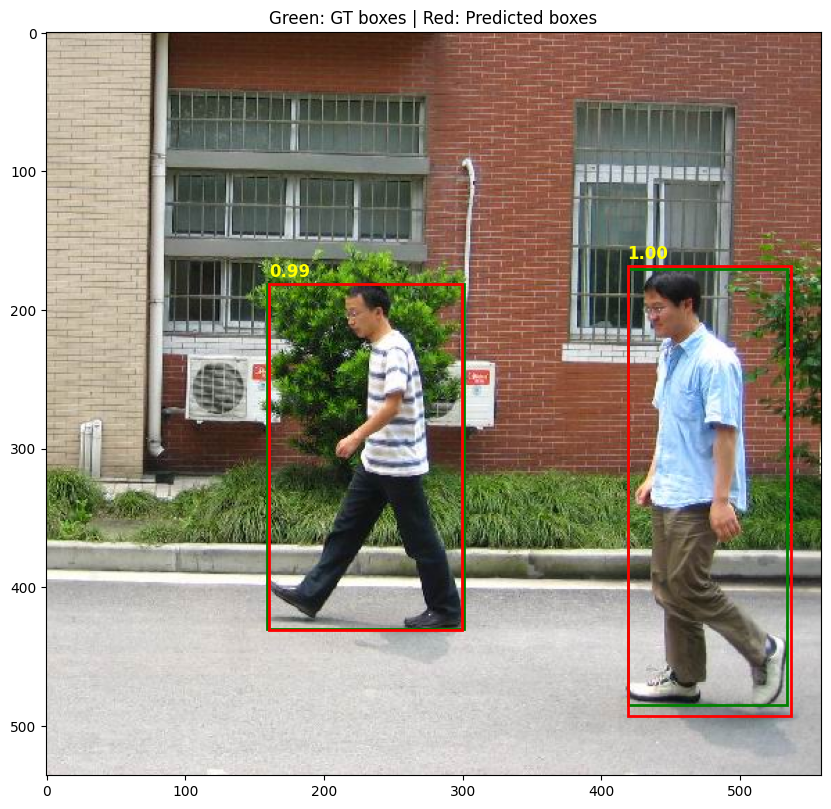

In [22]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from torchvision.ops import nms

# Get predictions
img, target = get_item(multi_obj_idx)
img, pred_boxes, labels, scores = get_predictions(multi_obj_idx, score_thresh=0.5)

# Apply NMS
if pred_boxes.numel() > 0:
    keep = nms(pred_boxes, scores, iou_threshold=0.5)
    pred_boxes = pred_boxes[keep]
    scores = scores[keep]

# Plot
fig, ax = plt.subplots(1, figsize=(10,10))
ax.imshow(img.permute(1,2,0))  # CHW -> HWC

# Ground truth boxes in green
for box in target["boxes"]:
    x1, y1, x2, y2 = box
    rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                             linewidth=2, edgecolor='g', facecolor='none')
    ax.add_patch(rect)

# Predicted boxes in red (only if any)
if pred_boxes.numel() > 0:
    for i, box in enumerate(pred_boxes):
        x1, y1, x2, y2 = box
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                 linewidth=2, edgecolor='r', facecolor='none')
        ax.add_patch(rect)
        ax.text(x1, y1-5, f"{scores[i]:.2f}", color='yellow', fontsize=12, weight='bold')

plt.title("Green: GT boxes | Red: Predicted boxes")
plt.show()

